# Part 2: Monte Carlo simulation of the stock price SDE

**Aim of this part**

The Feynman-Kac formula says the option price is also an expected value over random stock price paths. In this notebook we compute that expectation by simulation, using the methods of Sections 4.8 to 4.10 of the course notes. There are two separate sources of error, and the main goal is to measure each one on its own. The first is the statistical error from using a finite number of paths $M$, which should shrink like $M^{-1/2}$. The second is the time stepping bias from replacing the SDE by the Euler-Maruyama scheme, which should shrink like $\Delta t$. As in Part 1 we have the exact Black-Scholes price, so both errors can be measured rather than guessed.

In [1]:
import sys
import time
sys.path.append("..")

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

from pricing import black_scholes as bs
from pricing import sde
from pricing.plot_style import use_project_style, COLOURS, MARKERS, INK, GREY

use_project_style()

S0, K, r, sigma, T = 100.0, 100.0, 0.05, 0.2, 1.0
exact_call = bs.call_price(S0, K, r, sigma, T)
discount = np.exp(-r * T)
print(f"Exact call price {exact_call:.6f}")

# A fixed seed makes every number in this notebook repeatable (Section 4.5).
rng = np.random.default_rng(2500)

Exact call price 10.450584


**The risk neutral stock price model**

In the Black-Scholes model the stock price under the risk neutral measure follows geometric Brownian motion,

$$dS = rS\,dt + \sigma S\,dB_t,$$

which is an SDE of the form $dy = f(t,y)\,dt + g(t,y)\,dB_t$ from Section 4.9 with $f = rS$ and $g = \sigma S$. Itô's formula applied to $\ln S$ gives the exact solution

$$S(t) = S(0)\exp\left(\left(r - \tfrac{1}{2}\sigma^2\right)t + \sigma B_t\right),$$

so $\ln S(T)$ is normal with mean $\ln S(0) + (r - \frac{1}{2}\sigma^2)T$ and variance $\sigma^2T$. The Feynman-Kac formula expresses the PDE solution of Part 1 as

$$V(S_0, 0) = e^{-rT}\,\mathbb{E}\left[f(S(T))\right],$$

so the price is the discounted average payoff. We will only use the European call here. The digital behaves in the same way, with a smaller variance.

**Two ways to simulate**

Because the exact solution is known, we can sample $S(T)$ directly in a single step by drawing one standard normal $z$ and setting $S(T) = S_0\exp((r - \frac{1}{2}\sigma^2)T + \sigma\sqrt{T}z)$. The alternative, which is all we could do for an SDE without a closed form solution, is the Euler-Maruyama method from Section 4.9,

$$S_{n+1} = S_n + rS_n\Delta t + \sigma S_n\Delta B_n, \qquad \Delta B_n = z_n\sqrt{\Delta t}.$$

The function `simulate_terminal_prices` runs both at once, driving them with the same Brownian increments $\Delta B_n$. For the exact path it applies the solution formula over each step of length $\Delta t$. The only difference between the two final values is then the Euler-Maruyama discretisation error, which turns out to be the key to measuring it. The figure below shows four paths with 16 steps.

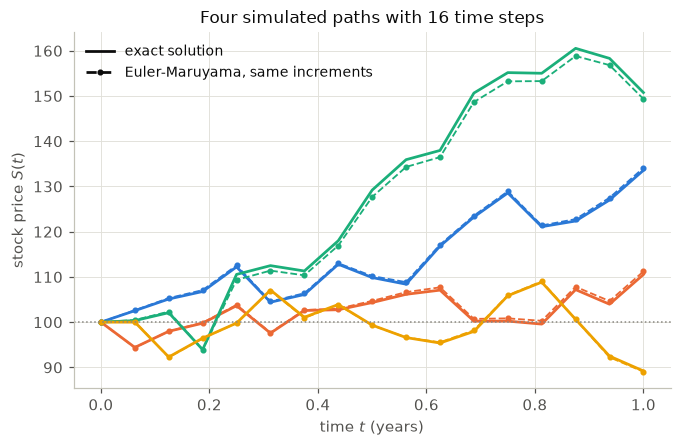

Final values, exact:          [133.564 110.53  150.762  89.213]
Final values, Euler-Maruyama: [134.085 111.202 149.353  89.034]


In [2]:
t, paths_exact, paths_em = sde.simulate_paths(S0, r, sigma, T, 16, 4, rng)

fig, ax = plt.subplots()
for i in range(4):
    ax.plot(t, paths_exact[i], "-", color=COLOURS[i], linewidth=1.8)
    ax.plot(t, paths_em[i], "--", color=COLOURS[i], marker="o", markersize=3, linewidth=1.2)
ax.axhline(K, color=GREY, linewidth=1, linestyle=":")
legend_lines = [Line2D([0], [0], color=INK, linestyle="-"), Line2D([0], [0], color=INK, linestyle="--", marker="o", markersize=3)]
ax.legend(legend_lines, ["exact solution", "Euler-Maruyama, same increments"])
ax.set_xlabel("time $t$ (years)")
ax.set_ylabel("stock price $S(t)$")
ax.set_title("Four simulated paths with 16 time steps")
fig.savefig("../figures/02_sample_paths.png")
plt.show()

print("Final values, exact:         ", np.round(paths_exact[:, -1], 3))
print("Final values, Euler-Maruyama:", np.round(paths_em[:, -1], 3))

With the same increments the two methods track each other closely, and the gap at $T$ is at most about a dollar on a stock price of around 100. Euler-Maruyama only drifts away from the exact path slowly, because its error per step is small compared with the random moves.

**Statistical error**

With $M$ independent samples $Y_i = e^{-rT}f(S_i(T))$, the estimate is the sample mean $\bar{Y}$ and its standard error is $s/\sqrt{M}$, where $s$ is the sample standard deviation (Section 4.10). By the central limit theorem $\bar{Y}$ is approximately normal, so $\bar{Y} \pm 1.96\,s/\sqrt{M}$ is an approximate 95% confidence interval for the price. The course notes estimate the error from the spread of $N$ independent runs. Using the spread of the individual samples is the same idea with each run being a single path, so we get an error bar from one run. Below we use exact sampling, so there is no bias and the standard error is the whole story. For each sample size $M$ we run 50 independent simulations. On the left each dot is one estimate and the shaded band is the exact price $\pm 1.96\,s/\sqrt{M}$, which should contain about 95% of the dots. On the right we plot the root mean square error over the 50 runs, which should match the standard error from a single run and fall like $M^{-1/2}$.

M =      100   RMS error over 50 runs = 1.58e+00   average standard error = 1.45e+00   runs inside the 95% band: 47 of 50
M =     1000   RMS error over 50 runs = 3.93e-01   average standard error = 4.62e-01   runs inside the 95% band: 50 of 50
M =    10000   RMS error over 50 runs = 1.51e-01   average standard error = 1.48e-01   runs inside the 95% band: 47 of 50
M =   100000   RMS error over 50 runs = 4.96e-02   average standard error = 4.66e-02   runs inside the 95% band: 47 of 50
M =  1000000   RMS error over 50 runs = 1.50e-02   average standard error = 1.47e-02   runs inside the 95% band: 46 of 50


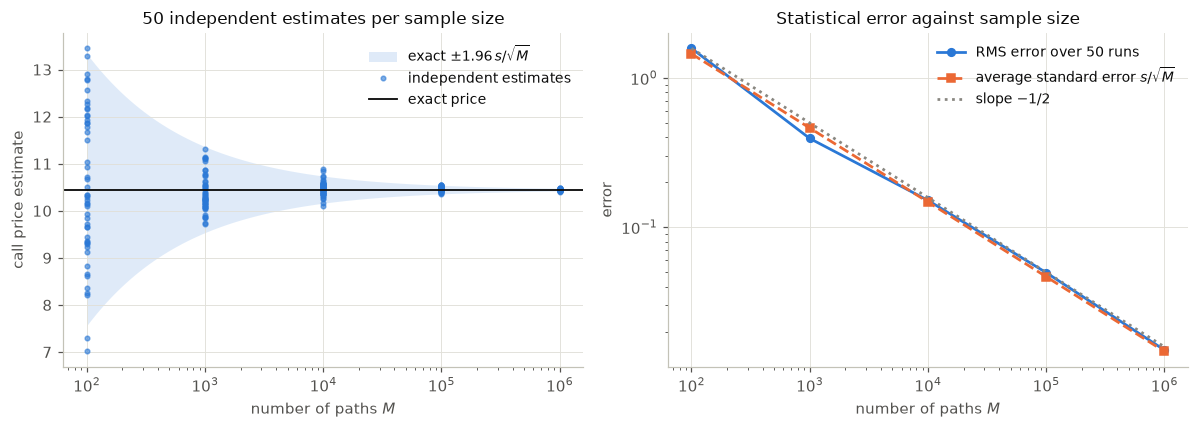

In [3]:
M_values = np.array([10**2, 10**3, 10**4, 10**5, 10**6])
n_repeats = 50
all_estimates = np.zeros((len(M_values), n_repeats))
all_std_errors = np.zeros((len(M_values), n_repeats))
for i, M in enumerate(M_values):
    for j in range(n_repeats):
        S_T = sde.sample_exact_terminal(S0, r, sigma, T, M, rng)
        all_estimates[i, j], all_std_errors[i, j] = sde.mc_estimate(discount * np.maximum(S_T - K, 0.0))

# Standard deviation of a single discounted payoff, used to draw the 95% band.
S_T = sde.sample_exact_terminal(S0, r, sigma, T, 1_000_000, rng)
s = np.std(discount * np.maximum(S_T - K, 0.0), ddof=1)

rms_errors = np.sqrt(np.mean((all_estimates - exact_call) ** 2, axis=1))
mean_std_errors = np.mean(all_std_errors, axis=1)
inside = np.abs(all_estimates - exact_call) < 1.96 * s / np.sqrt(M_values)[:, np.newaxis]
for i, M in enumerate(M_values):
    print(f"M = {M:8d}   RMS error over {n_repeats} runs = {rms_errors[i]:.2e}   average standard error = {mean_std_errors[i]:.2e}   runs inside the 95% band: {np.sum(inside[i])} of {n_repeats}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
M_fine = np.logspace(2, 6, 100)
axes[0].fill_between(M_fine, exact_call - 1.96 * s / np.sqrt(M_fine), exact_call + 1.96 * s / np.sqrt(M_fine),
                     color=COLOURS[0], alpha=0.15, linewidth=0, label=r"exact $\pm 1.96\,s/\sqrt{M}$")
for i, M in enumerate(M_values):
    label = "independent estimates" if i == 0 else None
    axes[0].plot(np.full(n_repeats, M), all_estimates[i], "o", color=COLOURS[0], markersize=3, alpha=0.6, label=label)
axes[0].axhline(exact_call, color=INK, linewidth=1.2, label="exact price")
axes[0].set_xscale("log")
axes[0].set_xlabel("number of paths $M$")
axes[0].set_ylabel("call price estimate")
axes[0].set_title(f"{n_repeats} independent estimates per sample size")
axes[0].legend()

axes[1].loglog(M_values, rms_errors, "o-", color=COLOURS[0], label=f"RMS error over {n_repeats} runs")
axes[1].loglog(M_values, mean_std_errors, "s--", color=COLOURS[1], label="average standard error $s/\\sqrt{M}$")
axes[1].loglog(M_values, rms_errors[0] * (M_values / M_values[0]) ** -0.5, ":", color=GREY, label="slope $-1/2$")
axes[1].set_xlabel("number of paths $M$")
axes[1].set_ylabel("error")
axes[1].set_title("Statistical error against sample size")
axes[1].legend()
fig.tight_layout()
fig.savefig("../figures/02_statistical_error.png")
plt.show()

The estimates form a funnel that narrows by a factor of $\sqrt{10} \approx 3.2$ for each tenfold increase in $M$, and nearly all of them fall inside the band. On the right the RMS error over repeated runs agrees with the standard error from a single run and follows the $M^{-1/2}$ line. This rate is the main weakness of Monte Carlo: each extra correct digit costs 100 times more paths. Even with $10^7$ paths the 95% error bar on the price would be about $\pm 0.01$, an accuracy the PDE solver of Part 1 beat with a few hundred grid points.

As a sharper check of the error bars, the interval $\bar{Y} \pm 1.96\,s/\sqrt{M}$ computed inside a single run should contain the exact price in about 95% of runs. The cell below counts this over 400 runs with $M = 10^4$.

In [4]:
n_runs, hits = 400, 0
run_estimates = []
for run in range(n_runs):
    S_T = sde.sample_exact_terminal(S0, r, sigma, T, 10_000, rng)
    estimate, std_error = sde.mc_estimate(discount * np.maximum(S_T - K, 0.0))
    run_estimates.append(estimate)
    if abs(estimate - exact_call) < 1.96 * std_error:
        hits += 1
print(f"Intervals containing the exact price: {hits} of {n_runs} ({100 * hits / n_runs:.1f}%)")
print(f"Spread of the run estimates (std over runs): {np.std(run_estimates, ddof=1):.4f}")
print(f"Typical standard error from a single run:    {std_error:.4f}")

Intervals containing the exact price: 382 of 400 (95.5%)
Spread of the run estimates (std over runs): 0.1450
Typical standard error from a single run:    0.1490


The coverage is close to 95% and the spread of the estimates between runs matches the standard error computed inside a single run, so the error bars mean what they claim.

**Time step bias of Euler-Maruyama**

For an SDE scheme there are two natural ways to measure the error at the final time. The strong error $\mathbb{E}\,|S_N - S(T)|$ measures how far each simulated path is from the exact path driven by the same Brownian motion. The weak error $|\mathbb{E}[f(S_N)] - \mathbb{E}[f(S(T))]|$ measures the error in an expected value, which is what an option price is. For Euler-Maruyama the standard results are strong order $\frac{1}{2}$ and weak order $1$ (Sauer Section 9.4, Higham 2001), so for pricing the relevant error is $O(\Delta t)$, like Euler's method for ODEs in Module 3.

For geometric Brownian motion we can see the first order bias by hand in the simplest expectation, $\mathbb{E}[S(T)]$. Each Euler-Maruyama step multiplies $S_n$ by $1 + r\Delta t + \sigma\Delta B_n$, whose mean is $1 + r\Delta t$, and the steps are independent, so

$$\mathbb{E}[S_N] = S_0(1 + r\Delta t)^N \quad\text{compared with}\quad \mathbb{E}[S(T)] = S_0e^{rT}.$$

Since $\ln(1 + r\Delta t) = r\Delta t - \frac{1}{2}r^2\Delta t^2 + \dots$, we get $(1 + r\Delta t)^N = e^{rT}\left(1 - \frac{1}{2}r^2T\Delta t + O(\Delta t^2)\right)$, so the bias is $-\frac{1}{2}S_0e^{rT}r^2T\,\Delta t$, which is first order in $\Delta t$.

In [5]:
print(" N   exact bias of E[S_N]   first order formula")
for N in [1, 2, 4, 8, 16, 32, 64, 128]:
    dt = T / N
    bias_mean = S0 * (1 + r * dt) ** N - S0 * np.exp(r * T)
    formula = -0.5 * S0 * np.exp(r * T) * r**2 * T * dt
    print(f"{N:3d}   {bias_mean:+.6e}        {formula:+.6e}")

 N   exact bias of E[S_N]   first order formula
  1   -1.271096e-01        -1.314089e-01
  2   -6.460964e-02        -6.570444e-02
  4   -3.257595e-02        -3.285222e-02
  8   -1.635672e-02        -1.642611e-02
 16   -8.195665e-03        -8.213055e-03
 32   -4.102175e-03        -4.106528e-03
 64   -2.052175e-03        -2.053264e-03
128   -1.026360e-03        -1.026632e-03


The bias of the mean halves each time the step halves, and the first order formula becomes exact as $\Delta t \to 0$. For the call payoff there is no such tidy formula, so we measure the bias by simulation.

Measuring the bias directly is harder than it looks. At $N = 64$ steps the bias of the call price turns out to be about $1.6 \times 10^{-3}$, while the standard error with $10^6$ independent paths is about $0.015$, so the bias is buried in the noise. Resolving it to within 10% would need around $10^{10}$ paths. The way around this is the coupling built into `simulate_terminal_prices`. Since the exact and Euler-Maruyama paths share their increments, we estimate the bias as the average of the differences $e^{-rT}\left(f(S_N) - f(S(T))\right)$ over paths. Each difference is small, of the size of the strong error, so its variance is tiny and $10^6$ paths are enough. This is a simple form of variance reduction by common random numbers.

Total simulation time: 15.1 s

  N   coupled bias (std error)     EM price - exact (std error)    strong error
   1   -2.523e-01 (2.7e-03)      -2.382e-01 (1.3e-02)        2.048e+00
   2   -9.158e-02 (1.8e-03)      -8.240e-02 (1.4e-02)        1.542e+00
   4   -3.925e-02 (1.2e-03)      -2.764e-02 (1.4e-02)        1.133e+00
   8   -1.593e-02 (8.6e-04)      -5.331e-03 (1.4e-02)        8.194e-01
  16   -7.134e-03 (6.1e-04)      +7.883e-03 (1.5e-02)        5.860e-01
  32   -3.873e-03 (4.3e-04)      +1.513e-02 (1.5e-02)        4.173e-01
  64   -1.606e-03 (3.0e-04)      -2.646e-03 (1.5e-02)        2.960e-01
 128   -1.185e-03 (2.1e-04)      +3.147e-03 (1.5e-02)        2.095e-01

Fitted weak order:   1.12
Fitted strong order: 0.47


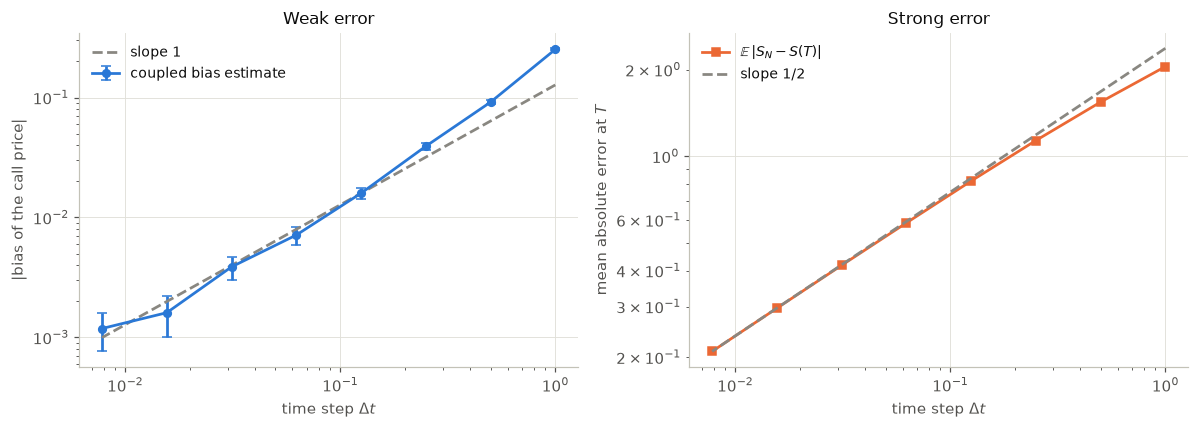

In [6]:
step_counts = np.array([1, 2, 4, 8, 16, 32, 64, 128])
M = 1_000_000
weak_bias, weak_se, strong_err, plain_err, plain_se = [], [], [], [], []

start = time.perf_counter()
for N in step_counts:
    S_exact, S_em = sde.simulate_terminal_prices(S0, r, sigma, T, N, M, rng)
    pay_exact = discount * np.maximum(S_exact - K, 0.0)
    pay_em = discount * np.maximum(S_em - K, 0.0)

    bias, bias_se = sde.mc_estimate(pay_em - pay_exact)  # coupled estimate of the bias
    price_em, price_se = sde.mc_estimate(pay_em)         # Euler-Maruyama price on its own

    weak_bias.append(bias)
    weak_se.append(bias_se)
    strong_err.append(np.mean(np.abs(S_em - S_exact)))
    plain_err.append(price_em - exact_call)
    plain_se.append(price_se)
print(f"Total simulation time: {time.perf_counter() - start:.1f} s")
print()
print("  N   coupled bias (std error)     EM price - exact (std error)    strong error")
for i, N in enumerate(step_counts):
    print(f"{N:4d}   {weak_bias[i]:+.3e} ({weak_se[i]:.1e})      {plain_err[i]:+.3e} ({plain_se[i]:.1e})        {strong_err[i]:.3e}")

weak_bias, weak_se, strong_err = np.array(weak_bias), np.array(weak_se), np.array(strong_err)
dt_values = T / step_counts
weak_order = np.polyfit(np.log(dt_values), np.log(np.abs(weak_bias)), 1)[0]
strong_order = np.polyfit(np.log(dt_values), np.log(strong_err), 1)[0]
print()
print(f"Fitted weak order:   {weak_order:.2f}")
print(f"Fitted strong order: {strong_order:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].errorbar(dt_values, np.abs(weak_bias), yerr=1.96 * weak_se, fmt="o-", color=COLOURS[0], capsize=3, label="coupled bias estimate")
axes[0].loglog(dt_values, np.abs(weak_bias[3]) * (dt_values / dt_values[3]), "--", color=GREY, label="slope 1")
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_xlabel(r"time step $\Delta t$")
axes[0].set_ylabel("|bias of the call price|")
axes[0].set_title("Weak error")
axes[0].legend()

axes[1].loglog(dt_values, strong_err, "s-", color=COLOURS[1], label=r"$\mathbb{E}\,|S_N - S(T)|$")
axes[1].loglog(dt_values, strong_err[-1] * (dt_values / dt_values[-1]) ** 0.5, "--", color=GREY, label="slope 1/2")
axes[1].set_xlabel(r"time step $\Delta t$")
axes[1].set_ylabel("mean absolute error at $T$")
axes[1].set_title("Strong error")
axes[1].legend()
fig.tight_layout()
fig.savefig("../figures/02_em_weak_strong.png")
plt.show()

With coupling, the bias is measured cleanly down to about 64 steps and falls at first order, with a fitted order of about 1.1. At 128 steps the error bar starts to be a noticeable fraction of the bias itself. The strong error falls at order one half, matching the theory. The middle column of the table shows why the coupling is needed. Without it, the difference between the Euler-Maruyama price and the exact price is dominated by statistical noise of about $0.015$ for every $N \ge 4$, and even has the wrong sign at some step counts, so it says nothing about the bias. The bias is negative, meaning Euler-Maruyama underprices the call, consistent with its underestimate of $\mathbb{E}[S(T)]$ above.

**Balancing bias and statistical error**

When the exact solution is not available, both errors are present at once, and for a fixed amount of work we have to decide how to split it between more paths and more time steps. Writing the bias as $c\,\Delta t = cT/N$ and the variance per path as $s^2$, the mean square error and the cost are

$$\text{MSE} = \left(\frac{cT}{N}\right)^2 + \frac{s^2}{M}, \qquad \text{cost} \propto MN.$$

To reach a root mean square error $\varepsilon$, a natural choice is to give half of the MSE to each term, so $N = \sqrt{2}\,cT/\varepsilon$ and $M = 2s^2/\varepsilon^2$, and the cost is $MN \propto \varepsilon^{-3}$. With exact sampling there is no bias, $N = 1$ and $M = s^2/\varepsilon^2$, so the cost is only $\varepsilon^{-2}$. This result is due to Duffie and Glynn (1995). The cell below uses our measured values of $c$ and $s$ to put numbers on it.

In [7]:
c = np.mean(np.abs(weak_bias[3:]) / dt_values[3:])  # bias is about c * dt for the finer steps
S_T = sde.sample_exact_terminal(S0, r, sigma, T, 1_000_000, rng)
s = np.std(discount * np.maximum(S_T - K, 0.0), ddof=1)
print(f"Measured bias constant c = {c:.3f},  payoff standard deviation s = {s:.2f}")
print()
print(" target RMS error   EM: steps   EM: paths   EM: normals drawn   exact: paths   ratio")
for eps in [1e-1, 1e-2, 1e-3]:
    N_em = int(np.ceil(np.sqrt(2) * c * T / eps))
    M_em = int(np.ceil(2 * s**2 / eps**2))
    M_exact = int(np.ceil(s**2 / eps**2))
    print(f"   {eps:8.0e}       {N_em:6d}    {M_em:10.2e}    {M_em * N_em:12.2e}       {M_exact:10.2e}   {M_em * N_em / M_exact:7.0f}")

Measured bias constant c = 0.124,  payoff standard deviation s = 14.71

 target RMS error   EM: steps   EM: paths   EM: normals drawn   exact: paths   ratio
      1e-01            2      4.33e+04        8.66e+04         2.16e+04         4
      1e-02           18      4.33e+06        7.79e+07         2.16e+06        36
      1e-03          176      4.33e+08        7.62e+10         2.16e+08       352


For a one cent accuracy the time stepped simulation needs about 36 times more random numbers than exact sampling, and for a tenth of a cent about 350 times more, so the gap grows like $1/\varepsilon$. For geometric Brownian motion this tells us never to time step, since the exact solution is available. The real message is about models where it is not, such as a volatility that depends on $S$ and $t$. There the bias cannot be avoided, and the $\varepsilon^{-3}$ cost of a first order scheme is what motivates higher order weak schemes and multilevel Monte Carlo.

**Discussion**

Monte Carlo pricing has two clearly separate error sources, and we measured each against the exact price. The statistical error behaved exactly as Section 4.10 predicts: it falls like $M^{-1/2}$, the standard error from a single run is a reliable error bar, and its 95% intervals cover the true price about 95% of the time. The Euler-Maruyama bias fell at first order, as the weak order theory predicts, but it could only be seen by coupling the exact and approximate paths through common random numbers. Without that, a bias of $10^{-3}$ is invisible under noise of $10^{-2}$. Putting the two together, a first order scheme makes the total cost grow like $\varepsilon^{-3}$ instead of $\varepsilon^{-2}$.

Compared with the PDE of Part 1, Monte Carlo is slow in one dimension: $10^7$ paths give a price to about $\pm 0.01$, while the Crank-Nicolson solver with Rannacher smoothing reached $10^{-4}$ on a grid of 1600 points in a fraction of a second. Its advantages are that it needs no grid, no boundary conditions and no stability analysis, and that its error bar comes for free. Part 3 shows why the convergence rate $M^{-1/2}$, slow as it is, becomes decisive when there are many underlying assets.